# Trabajo Práctico Nº 1
## Objetivos

- Implementar y analizar el filtro de promedio móvil (moving average) en Python.
- Aplicar el concepto de convolución en señales digitales.
- Familiarizarse con el entorno de desarrollo en Python notebooks.
- Comparar representación en punto flotante vs punto fijo, evaluando precisión y tiempos de cómputo.

# Ejercicio 1 - Filtro Moving Average

1. Implementá un algoritmo de promedio móvil (moving average) según la definición vista en clase, que reciba como parámetros:

- La señal de entrada.
- El tamaño de la ventana.

A partir de tu implementación, obtené y graficá la respuesta impulsiva del sistema (lo que en clase llamamos su “firma” o función de transferencia).

2. Respondé:

- ¿Cómo se obtiene la respuesta impulsiva de cualquier sistema?
- ¿Qué representa en el caso del filtro de promedio móvil?

Tomando el concepto de Moving Average

$$y[n] = {1 \over {M+N+1}} \sum_{k=-M}^N x[n-k]$$

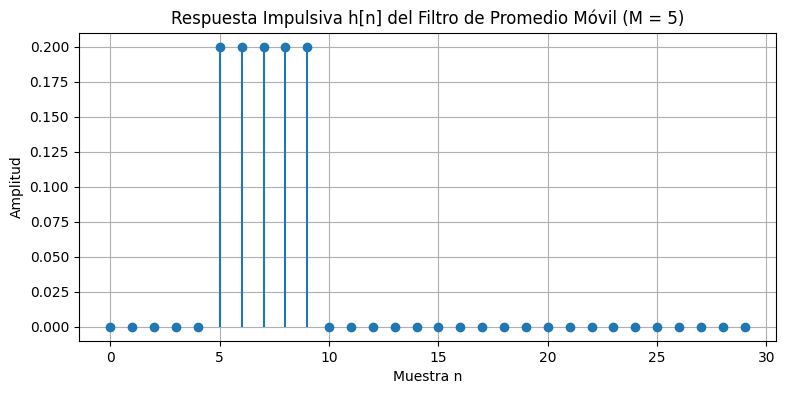

In [6]:
# Escribí tu código acá

#Importo librerias necesarias
import numpy as np
import matplotlib.pyplot as plt

#Definición de la moving average

def mov_avg(x,M):
  N=len(x) #Cantidad total de muestras de la señal de entrada
  y= np.zeros(N,dtype=np.float64) #vector de ceros para almacenar la salida ya filtrada

  for n in range(N):
    i = max(0,n-M+1) #se utiliza para evitar indices negativos en la muestra
    y[n]= np.sum(x[i:n+1])/M
  return y

#definición de parametros

L = 30
M = 5
delta = np.zeros(L)
delta[5] = 1.0 #Impulso unitario centrado en n=5

h=mov_avg(delta,M) #Excitación del sistema, la salida de "h" es la firma del sistema

#Gráficos

plt.figure(figsize=(9, 4))
plt.stem(range(L), h, basefmt=" ")
plt.title(f'Respuesta Impulsiva h[n] del Filtro de Promedio Móvil (M = {M})')
plt.xlabel('Muestra n')
plt.ylabel('Amplitud')
plt.grid(True)
plt.show()


## Respuestas teóricas:

### 1- ¿Cómo se obtiene la respuesta impulsiva de cualquier sistema?

Se obtiene excitando la entrada del sistema en reposo con un impulso unitario (o delta de dirac en tiempo discreto).

En el dominio de la frecuencia su transformada DTFT satisface la siguiente igualdad:
 $$D(w)=1$$

En el dominio frecuencial la DTFT de la delta vale $1$ para todas las frecuencias. Al contener todas las componentes con amplitud unitaria, la salida resultante $h[n]$ nos entrega directamente la respuesta al impulso o la "firma" del sistema:


$$h[n] = T\{\delta[n]\}$$





### 2 -¿Qué representa en el caso del filtro de promedio móvil?

Representa un pulso rectangular con ancho de $M$ muestras y una amplitud constante de $1/M$. Esto nos muestra que el promedio móvil es un filtro FIR (de respuesta impulsiva finita), donde cada una de las muestras pasadas tiene exactamente el mismo peso o coeficiente de ponderación.

# Ejercicio 2 - Respuesta del sistema

1. Genera dos señales de prueba:
    - Una onda cuadrada de amplitud 1 y frecuencia de 2 kHz.
    - Una onda triangular de amplitud 1 y frecuencia de 1 kHz.

Aplica el moving average implementado en el Ejercicio 1 a estas señales.

2. Analiza los resultados:

    - Grafica la señal original y la señal filtrada.
    - Explica qué cambios observas en la forma de onda.

3. Escribe tus conclusiones: ¿qué efecto tiene el filtro de promedio móvil sobre cada señal?


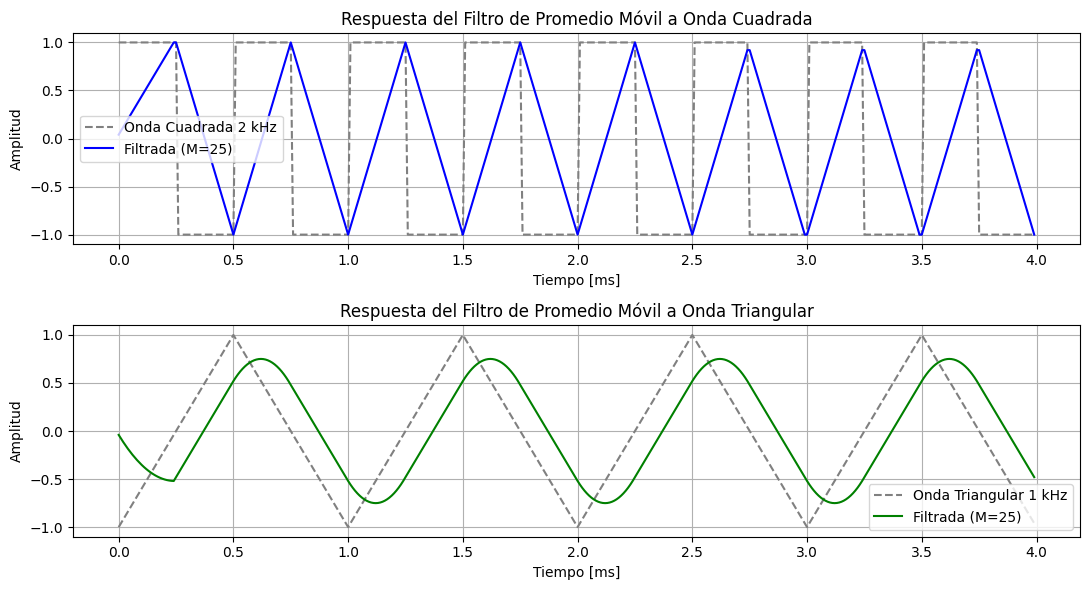

In [7]:
# Escribí tu código acá

#Importo librerias necesarias
import numpy as np
import matplotlib.pyplot as plt

#Definición de la moving average

def mov_avg(x,M):
  N=len(x) #Cantidad total de muestras de la señal de entrada
  y= np.zeros(N,dtype=np.float64) #vector de ceros para almacenar la salida ya filtrada

  for n in range(N):
    i = max(0,n-M+1) #se utiliza para evitar indices negativos en la muestra
    y[n]= np.sum(x[i:n+1])/M
  return y

#Defino parámetros
fs = 100000        # Se elige esta frecuencia de muestreo para evitar aliasing
T_total = 0.004    # 4 ms
t = np.arange(0, T_total, 1/fs)

#Defino la Onda cuadrada (2 kHz, amplitud 1)
f_sq = 2000 #2 KHz
seno_aux = np.sin(2 * np.pi * f_sq * t)
cuadrada = np.where(seno_aux >= 0, 1.0, -1.0)

#Defino la Onda triangular (1 kHz, amplitud 1)
f_tri = 1000 #1 KHz
triangular = 2 * np.abs(2 * (t * f_tri - np.floor(t * f_tri + 0.5))) - 1

# Filtrado con ventana
M = 25
cuadrada_filt = mov_avg(cuadrada, M)
triangular_filt = mov_avg(triangular, M)

# Gráficos
plt.figure(figsize=(11, 6))
plt.subplot(2, 1, 1)
plt.plot(t * 1e3, cuadrada, label='Onda Cuadrada 2 kHz', color='gray', linestyle='--')
plt.plot(t * 1e3, cuadrada_filt, label=f'Filtrada (M={M})', color='blue', linewidth=1.5)
plt.title('Respuesta del Filtro de Promedio Móvil a Onda Cuadrada')
plt.xlabel('Tiempo [ms]')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(t * 1e3, triangular, label='Onda Triangular 1 kHz', color='gray', linestyle='--')
plt.plot(t * 1e3, triangular_filt, label=f'Filtrada (M={M})', color='green', linewidth=1.5)
plt.title('Respuesta del Filtro de Promedio Móvil a Onda Triangular')
plt.xlabel('Tiempo [ms]')
plt.ylabel('Amplitud')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Cambios observados en la forma de onda:

Onda Cuadrada: Esta pierde presenta flancos de subida y bajada que ya no son instantaneos y pasan a tener pendientes continuas con forma de rampa, a medida se amplia el valor M (ancho de ventana) se asemeja cada vez más a una triangular. Por ejemplo: con M=25 ya cambia totalmente a ser una onda cuasitriangular.


Onda triangular: Los picos presentes en la onda se suavizan más a medida que el valor de M crece, con el mismo valor, M=25 ya presenta una forma de onda cuasisenoidal.

En ambas ondas se puede observar un desplazamiento temporal hacía la derecha, esto se debe a que el filtro introduce una demora de:

 $$(M-1) \over 2$$

 El filtro de promedio movil modifica el contenido espectral de la señal, en este caso actua como pasa bajos ya que elimina el ruido de alta frecuencia, ambas señales presentan bordes o picos agudos (considerados armónicos de alta frecuencia) y al pasar por el filtro, estas frecuencias se recortan, transformando ambas señales como se detalló anteriormente.

# Ejercicio 3 - Convolución en punto flotante y punto fijo

1. Implementa un algoritmo de convolución:

    - En punto flotante (float).
    - En punto fijo, utilizando la funcion fijo() de ejemplo.

2. Compara los resultados con la función de NumPy np.convolve. Mide y compara:

    - El tiempo de ejecución usando timeit.
    - El error de la salida respecto al cálculo en punto flotante.

3. Graficar todas las señales calculadas

4. Conclusión:

    - ¿Qué diferencias observas entre las implementaciones?
    - ¿Qué conclusiones se puede sacar de usar punto fijo vs punto flotante?

Tiempo NumPy (np.convolve): 0.000063 s
Tiempo Float manual: 0.001734 s
Tiempo Punto Fijo manual: 0.002801 s
Error NumPy vs Float manual: 3.13e-33
Error Punto Fijo vs Float: 3.65e-10


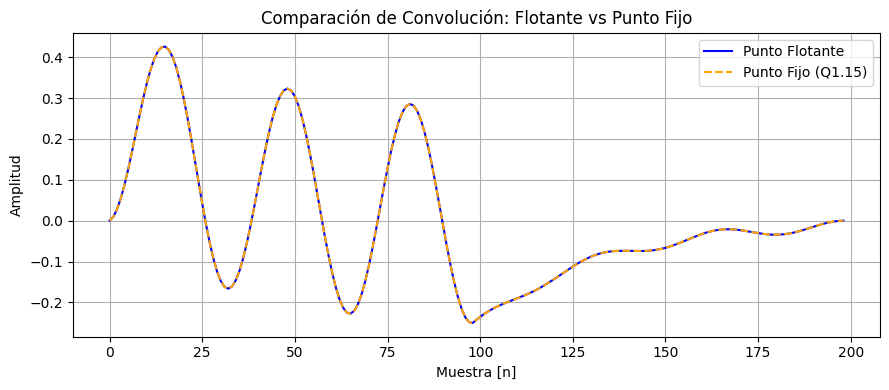

In [8]:
# Escribí tu código acá

#importo librerias
import numpy as np
import matplotlib.pyplot as plt
import timeit

def fijo(x, frac_bits=15):
    """Convierte float a entero Q1.15 con saturación."""
    xf = np.round(x * (1 << frac_bits)).astype(np.int32)
    return np.clip(xf, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)

# Convolución manual en Punto Flotante
def conv_float_manual(x, h):
    Nx, Nh = len(x), len(h)
    Ny = Nx + Nh - 1
    y = np.zeros(Ny, dtype=np.float64)
    for n in range(Ny):
        acum = 0.0
        for k in range(Nh):
            if 0 <= n - k < Nx:
                acum += x[n - k] * h[k]
        y[n] = acum
    return y

# Convolución manual en Punto Fijo (Q1.15)
def conv_fijo_manual(x_q, h_q, frac_bits=15):
    Nx, Nh = len(x_q), len(h_q)
    Ny = Nx + Nh - 1
    y_q = np.zeros(Ny, dtype=np.int16)

    for n in range(Ny):
        acc = int(0)
        for k in range(Nh):
            if 0 <= n - k < Nx:
                acc += int(x_q[n - k]) * int(h_q[k])

        # Desescalado (>> 15) por el producto de dos números Q1.15
        acc_desescalado = acc >> frac_bits
        # Aritmética saturada
        y_q[n] = np.clip(acc_desescalado, -32768, 32767)
    return y_q


#señales de prueba

N_pts = 100
t = np.linspace(0, 1, N_pts)

s1 = 0.25 * np.sin(2 * np.pi * 3 * t)
s2 = 0.20 * np.exp(-3 * t)

# Conversión a punto fijo
s1_fijo = fijo(s1)
s2_fijo = fijo(s2)

# Wrapper de medición
def wrapper(func, *args):
    def wrapped():
        return func(*args)
    return wrapped

# Medición de tiempos de ejecución
conv_np_wrap   = wrapper(np.convolve, s1, s2)
conv_flt_wrap  = wrapper(conv_float_manual, s1, s2)
conv_fijo_wrap = wrapper(conv_fijo_manual, s1_fijo, s2_fijo)

t_numpy = timeit.timeit(conv_np_wrap, number=1)
t_float = timeit.timeit(conv_flt_wrap, number=1)
t_fijo  = timeit.timeit(conv_fijo_wrap, number=1)

# Cálculo de las salidas
y_numpy = np.convolve(s1, s2)
y_float = conv_float_manual(s1, s2)
y_fijo_raw = conv_fijo_manual(s1_fijo, s2_fijo)

# Reescalado a float
y_fijo_float = y_fijo_raw.astype(np.float64) / (1 << 15)

# Error cuadrático medio respecto a punto flotante
error_np_vs_float = np.mean((y_numpy - y_float)**2)
error_fijo_vs_float = np.mean((y_float - y_fijo_float)**2)

print(f"Tiempo NumPy (np.convolve): {t_numpy:.6f} s")
print(f"Tiempo Float manual: {t_float:.6f} s")
print(f"Tiempo Punto Fijo manual: {t_fijo:.6f} s")
print(f"Error NumPy vs Float manual: {error_np_vs_float:.2e}")
print(f"Error Punto Fijo vs Float: {error_fijo_vs_float:.2e}")


#Gráficos de las señales calculadas

plt.figure(figsize=(9, 4))
plt.plot(y_float, label='Punto Flotante', color='blue', linewidth=1.5)
plt.plot(y_fijo_float, label='Punto Fijo (Q1.15)', color='orange', linestyle='--', linewidth=1.5)
plt.title('Comparación de Convolución: Flotante vs Punto Fijo')
plt.xlabel('Muestra [n]')
plt.ylabel('Amplitud')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### ¿Qué diferencias observas entre las implementaciones?


La implementación con np.convolve es significativamente más rápida debido a que ejecuta rutinas vectorizadas y precompiladas en C de bajo nivel

La convolución manual en punto fijo tarda más que en un punto flotante debido a que existe un costo extra de simular por software los desplazamientos a nivel de bit y la función para la saturación (np.clip)

Si se utilizara un hardware real (DSP) las operaciones en punto fijo se resolverían solo en un ciclo de clock, lo que las hace mucho más rápidas y con menor consumo que emular flotante por software.


### ¿Qué conclusiones se puede sacar de usar punto fijo vs punto flotante?

El punto flotante tiene un rango dinámico más amplio y prácticamente elimina el overflow (riesgo de desborde) gracias a que tiene exponente variable. En cambio, el punto fijo tiene un rango acotado y resolución fija, esto introduce ruido de cuantización y obliga a utilizar acumuladores más anchos para evitar oscilaciones y desbordes.

En el apartado de hardware, el punto fijo requiere algo más simple, menor consumo de potencia y chips más económicos, sin embargo el desarrollo es más complejo ya que exige controlar manualmente las escalas de las variables, por el lado del punto flotante facilita y acelera la progamación al no requerir escalados, pero demanda un hardware más complejo y costoso.


In [9]:
# Ejemplos de medicion de tiempos
# %pylab inline
import timeit
import time
import numpy as np

t = np.arange(0, 1024/20000, 1/20000)
s1= np.sin(2*np.pi*1000*t)+1
s2 = np.sin(2*np.pi*1200*t)

# METODO 1 de medición de tiempos

# Este wrapper empaqueta funciones para que el timeit pueda medir solo eso
def wrapper(func, *args):
    def wrapped():
        return func(*args)
    return wrapped

conv = wrapper(np.convolve, s1, s2)
print (timeit.timeit(conv, number=1))

# METODO 2 de medición de tiempos
start = time.time()
conv_r = np.convolve(s1,s2)
end = time.time()
print (end-start)

0.0001471000723540783
0.0005018711090087891


Float => Max: 1.0, Min: -1.0
Fijo => Max: 32767, Min: -32768


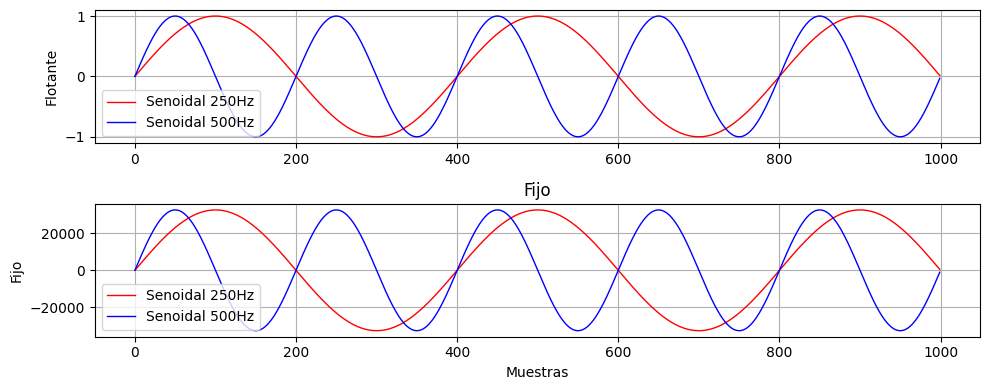

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import timeit

fs = 100000      # Frecuencia de muestreo
N = 1000        # Duración total
t = np.arange(0,N/fs,1/fs)

f1 = 250
f2 = 500

# Conversión a punto fijo
def fijo(x, frac_bits=15):
    """Convierte float a entero Q1.15 con saturación."""
    xf = np.round(x * (1 << frac_bits)).astype(np.int32)
    return np.clip(xf, -(1 << frac_bits), (1 << frac_bits) - 1).astype(np.int16)

x = np.sin(2*np.pi*f1*t)
y = np.sin(2*np.pi*f2*t)

xf = fijo(x)
yf = fijo(y)

print(f"Float => Max: {max(x)}, Min: {min(x)}")
print(f"Fijo => Max: {max(xf)}, Min: {min(xf)}")

plt.figure(figsize=(10, 4))
plt.subplot(2,1,1)
plt.plot(t*fs, x, label='Senoidal 250Hz', color='red', linewidth=1)
plt.plot(t*fs, y, label='Senoidal 500Hz', color='blue', linewidth=1)
plt.ylabel("Flotante")
plt.legend()
plt.grid(True)
plt.subplot(2,1,2)
plt.plot(t*fs, xf, label='Senoidal 250Hz', color='red', linewidth=1)
plt.plot(t*fs, yf, label='Senoidal 500Hz', color='blue', linewidth=1)
plt.legend()
plt.grid(True)
plt.title("Fijo")
plt.ylabel("Fijo")
plt.xlabel("Muestras")
plt.tight_layout()
plt.show()